# One-of-a-Kind Pitches (2024–2026)

**Question:** Which pitches are the *most unique* compared with pitches thrown by **other pitchers**, judged on velocity, movement, and arm angle (`ball_angle`)?

**Idea:** for every pitch, find its **closest twin**, meaning the most similar pitch thrown by somebody else. A pitch is unique if even its closest twin is far away.

**Roadmap**
1. **Prep:** choose the features and fix a sign problem in horizontal break.
2. **Measuring distance:** put every feature on the same scale and compute how far apart every pair of pitches is.
3. **Uniqueness, five ways:** distance to the closest twin, average distance to the 5 closest, pitch shape only (no arm angle), cosine-based, and within pitch type.
4. **Summary** of every method's answer.

Pitch-type codes: FF four-seam · SI sinker · FC cutter · SL slider · ST sweeper · SV slurve · CU curveball · CH changeup · FS splitter · FO forkball · KN knuckleball

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
DERIVED = Path("derived")

%config InlineBackend.figure_format = 'retina'

# Chart colors: gray = "every other pitch", blue/orange = the pitches we're pointing at
GRAY, BLUE, ORANGE = '#c3c2b7', '#2a78d6', '#eb6834'
INK, SUBTLE = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': SUBTLE, 'axes.titlecolor': INK,
    'xtick.color': '#898781', 'ytick.color': '#898781',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

# Pitch-type colors. Pitch types whose clusters touch on the charts (sinker vs. changeup, cutter vs. slider, ...)
# get colors that colorblind readers can still tell apart. To match Visualizations.ipynb instead,
# paste its PITCH_COLORS here (keep an 'Other' entry).
PITCH_ORDER = ['FF', 'SI', 'FC', 'SL', 'ST', 'CU', 'CH', 'FS']
PITCH_COLORS = {'FF': '#008300', 'SI': '#1baf7a', 'FC': '#e87ba4', 'SL': '#eda100', 'ST': '#e34948',
                'CU': '#2a78d6', 'CH': '#6250d6', 'FS': '#eb6834', 'Other': '#898781'}
PITCH_NAMES = {'FF': 'Four-seam', 'SI': 'Sinker', 'FC': 'Cutter', 'SL': 'Slider', 'ST': 'Sweeper',
               'CU': 'Curveball', 'CH': 'Changeup', 'FS': 'Splitter', 'SV': 'Slurve', 'FO': 'Forkball',
               'KN': 'Knuckleball', 'Other': 'Other (SV, FO, KN)'}

In [2]:
data = pd.read_csv(DERIVED / 'data24-26.csv')
print(data.shape)
data[['name', 'year', 'hand', 'pitch_type', 'n_pitches', 'avg_speed',
      'pitcher_break_x', 'pitcher_break_z_induced', 'ball_angle']].head(8)

(3677, 53)


,name,year,hand,pitch_type,n_pitches,avg_speed,pitcher_break_x,pitcher_break_z_induced,ball_angle
0,"Webb, Logan",2024,R,SI,1270,92.6,15.1,1.1,22.1
1,"Webb, Logan",2024,R,CH,990,87.4,9.8,-4.8,22.1
2,"Webb, Logan",2024,R,ST,680,83.8,16.4,-0.9,22.1
3,"Webb, Logan",2024,R,FF,176,92.6,8.6,9.2,22.1
4,"Nola, Aaron",2024,R,CU,1049,79.1,14.0,-9.9,20.1
5,"Nola, Aaron",2024,R,FF,883,92.5,12.0,14.7,20.1
6,"Nola, Aaron",2024,R,SI,656,91.5,16.9,8.6,20.1
7,"Nola, Aaron",2024,R,CH,307,85.7,15.3,3.2,20.1


---
## Part 1: Preparing the data

### Step 1a: What is one observation?
Each row is **one pitcher's pitch type in one season** (for example, Logan Webb's 2024 sinker). Those are the things we'll compare. The four metrics from the question:

| column | what it measures |
|---|---|
| `avg_speed` | average velocity (mph) |
| `pitcher_break_x` | horizontal break (inches) |
| `pitcher_break_z_induced` | induced vertical break, or IVB (inches): vertical movement from spin, with gravity removed |
| `ball_angle` | arm angle (degrees): 90 = straight over the top, 0 = sidearm, negative = submarine |

Before using `ball_angle`, check whether it changes from pitch to pitch or is one number per pitcher:

In [3]:
# How many different ball_angle values does one pitcher have in one season?
data.groupby(['id', 'year'])['ball_angle'].nunique().value_counts()

ball_angle
1    847
Name: count, dtype: int64

**Every pitcher-season has exactly one arm angle.** So arm angle can't tell a pitcher's own pitches apart, but it *does* tell different pitchers apart, and the question is about different pitchers. Keep that in mind: it will matter a lot in Part 3.

### Step 1b: Horizontal break has no direction

In [4]:
data.groupby('pitch_type')['pitcher_break_x'].agg(['count', 'mean', 'min', 'max']).round(1)

,count,mean,min,max
pitch_type,,,,
CH,526,14.1,1.7,19.3
CU,425,8.8,0.1,19.0
FC,347,2.4,0.0,13.0
FF,771,7.9,0.0,17.6
FO,3,8.1,3.2,11.2
FS,134,10.8,0.7,17.5
KN,2,7.1,5.6,8.6
SI,583,14.9,1.0,18.9
SL,529,4.3,0.0,15.3


`pitcher_break_x` is **never negative.** Sinkers average ~15 inches and sweepers ~14 inches, so they look nearly the same, yet they break in **opposite directions** (a sinker runs toward the pitcher's arm side, a sweeper toward his glove side). Any similarity measure would call a sinker and a sweeper twins. That has to be fixed first.

**Fix:** reuse the sign logic from `movement_plot()` in `Visualizations.ipynb`. `league_break_x` *is* signed (negative = arm side), and `diff_x` tells us whether this pitch broke the same way as the league average.

**One design choice:** I code the result as **arm side = positive, glove side = negative**, not "toward 1B / toward 3B". That way a lefty's slider and a righty's slider count as the *same* pitch, mirror images from the pitcher's point of view. (Part 2 checks what happens if we only compare same-handed pitchers.)

In [5]:
# Same logic as movement_plot() in Visualizations.ipynb, minus the final L/R flip
league_dir = np.where(data['league_break_x'] < 0, 1, -1)              # which way the league average breaks: +1 = arm side
league_dir = np.where(data['league_break_x'].isna(), 1, league_dir)   # forkballs have no league average: they break arm side
toward_league = data['league_break_x'].abs() + data['diff_x']         # < 0 means this pitch broke the OPPOSITE way
same_dir = np.where(toward_league.isna() | (toward_league >= 0), 1, -1)
data['arm_break'] = data['pitcher_break_x'] * league_dir * same_dir

data.groupby('pitch_type')['arm_break'].agg(['count', 'mean', 'min', 'max']).round(1)

,count,mean,min,max
pitch_type,,,,
CH,526,14.1,1.7,19.3
CU,425,-8.7,-19.0,3.2
FC,347,-1.9,-13.0,6.0
FF,771,7.9,-2.7,17.6
FO,3,8.1,3.2,11.2
FS,134,10.8,0.7,17.5
KN,2,7.1,5.6,8.6
SI,583,14.9,1.0,18.9
SL,529,-4.2,-15.3,4.1


**Sanity check passes:** four-seamers, sinkers, changeups and splitters are positive (arm side). Sliders, sweepers, curveballs and slurves are negative (glove side). Cutters sit just to the glove side of zero.

### Step 1c: Pitch-type colors for the Part 3 charts
The Part 3 charts color each pitch by its type. This cell sets up that coloring (SV, FO and KN have only 28 rows combined, so they share one gray "Other" color).

*About the colors:* they were checked numerically so that pitch types whose clusters touch stay distinguishable for colorblind readers too. They differ from the Baseball Savant colors used in `Visualizations.ipynb` (Savant's yellow slider is nearly invisible on a white background). To match that notebook, replace `PITCH_COLORS` in the setup cell.

In [6]:
# SV, FO and KN have only 28 rows between them, so they share one "Other" color
data['type_group'] = np.where(data['pitch_type'].isin(PITCH_ORDER), data['pitch_type'], 'Other')


# On velocity charts the CH, FS and SL clusters are centered almost on the same spot (~86 mph),
# so their labels get nudged up/down (in inches of vertical break) to keep them readable
NUDGE_VELO = {'CH': (0, 2.0), 'SL': (0, -2.0)}


def pitch_scatter(ax, df, x, y, size=10, alpha=0.75, type_labels=True, nudge={}):
    '''Scatter df[x] vs df[y] with one color per pitch type.
    type_labels=True writes each type's code at the middle of its cluster (nudge moves a label by (dx, dy)).
    size can be one number or a column of per-pitch sizes.'''
    for t in PITCH_ORDER + ['Other']:
        sub = df[df['type_group'] == t]
        s = size if np.isscalar(size) else size.loc[sub.index]
        ax.scatter(sub[x], sub[y], s=s, color=PITCH_COLORS[t], alpha=alpha, edgecolor='white', linewidth=0.3)
    if type_labels:
        for t in PITCH_ORDER:
            sub = df[df['type_group'] == t]
            dx, dy = nudge.get(t, (0, 0))
            ax.text(sub[x].median() + dx, sub[y].median() + dy, t, ha='center', va='center', fontsize=9,
                    fontweight='bold', color=INK,
                    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=PITCH_COLORS[t], lw=1.5, alpha=0.9))


def pitch_legend(ax, types=None, **kwargs):
    '''Legend with one colored dot per pitch type. Works on an axis or a whole figure.'''
    if types is None:
        types = PITCH_ORDER + ['Other']
    handles = [plt.Line2D([], [], marker='o', ls='', markersize=7, color=PITCH_COLORS[t],
                          label=PITCH_NAMES[t] if t == 'Other' else f'{t} {PITCH_NAMES[t]}')
               for t in types]
    return ax.legend(handles=handles, frameon=False, **kwargs)

### Step 1d: The final features

In [7]:
FEATURES = ['avg_speed', 'arm_break', 'pitcher_break_z_induced', 'ball_angle']
data['label'] = data['name'] + ' ' + data['year'].astype(str) + ' ' + data['pitch_type']

data[FEATURES].describe().round(1)

,avg_speed,arm_break,pitcher_break_z_induced,ball_angle
count,3677.0,3677.0,3677.0,3677.0
mean,88.3,3.3,5.2,37.7
std,5.7,10.4,8.2,11.7
min,71.0,-20.3,-18.0,-64.1
25%,84.2,-4.9,0.6,31.2
50%,88.3,5.5,5.7,38.6
75%,93.2,13.2,11.3,45.2
max,101.4,19.3,21.2,70.1


The four features are on **very different scales**. Velocity sits around 88 with an SD of ~6, while break is centered near 0–5. If we compared raw numbers, velocity would drown out everything else, so Part 2 standardizes them.

### Step 1e: Two ground rules
1. **"A pitch by another individual."** We never compare a pitch with another pitch from the *same pitcher*, including his own pitch in a different year. Otherwise Logan Webb's 2024 sinker vs. his 2025 sinker would win easily, and that answer is useless.
2. **Keep every row for now** (every pitch type thrown at least ~50 times). Small samples give noisier averages, the end of Part 3 re-runs the analysis on `pitch_type_qualified` pitches only (300+ thrown, 50+ PA) to check that the answer holds up.

### Step 1f: Helper functions
Every method in this notebook produces a **3,677 × 3,677 matrix**: row *i*, column *j* compares pitch *i* with pitch *j*. These helpers blank out same-pitcher pairs and pull out each pitch's closest twin.

In [8]:
def blank_out(df, scores, only_same=None):
    '''Copy of a pitch-by-pitch score matrix with the pairs we don't want set to NaN.
    Always removes same-pitcher pairs (which also removes each pitch vs. itself).
    only_same='year' or 'hand' also removes pairs that differ on that column.'''
    scores = scores.astype(float).copy()
    ids = df['id'].to_numpy()
    scores[np.equal.outer(ids, ids)] = np.nan          # True wherever row pitcher == column pitcher
    if only_same is not None:
        col = df[only_same].to_numpy()
        scores[~np.equal.outer(col, col)] = np.nan
    return scores


def find_twins(df, scores, best, only_same=None):
    '''For every pitch in df, find its twin: the most similar pitch thrown by a DIFFERENT pitcher.
    best='max' if a bigger score means more similar (cosine similarity)
    best='min' if a smaller score means more similar (distance)'''
    scores = blank_out(df, scores, only_same)
    if best == 'max':
        twin = np.nanargmax(scores, axis=1)
    else:
        twin = np.nanargmin(scores, axis=1)

    twins = pd.DataFrame({'pitch': df['label'].to_numpy(),
                          'twin': df['label'].to_numpy()[twin],
                          'score': scores[np.arange(len(df)), twin],
                          'row': np.arange(len(df)),
                          'twin_row': twin})
    # If A's twin is B and B's twin is A, the pair shows up twice -> give each pair one id
    twins['pair'] = [tuple(sorted(p)) for p in zip(twins['row'], twins['twin_row'])]
    return twins


def top_pairs(twins, best, n=10):
    '''The n pitches with the closest twins, keeping each pair only once.'''
    return twins.sort_values('score', ascending=(best == 'min')).drop_duplicates('pair').head(n)


def side_by_side(df, rows):
    '''Raw feature values for a few pitches, so we can see how similar they really are.'''
    return df.loc[rows, ['label', 'team', 'hand', 'n_pitches'] + FEATURES]

---
## Part 2: Measuring how far apart pitches are

**Step 2a: Standardize (z-scores).** Convert every feature to $z = \frac{x - \text{league mean}}{\text{league SD}}$. Each feature is now measured in standard deviations, so 1 SD of velocity counts the same as 1 SD of break. Without this, velocity (always 70–101) would dominate every comparison.

**Step 2b: Two ways to compare two pitches.**
* **Euclidean distance:** the straight-line distance between two pitches in z-score space, $d(a,b) = \sqrt{\sum_k (z_{a,k} - z_{b,k})^2}$. 0 means identical; the units are SDs. This is the main measure in Part 3.
* **Cosine similarity:** the angle between two pitches' z-score "arrows," measuring whether they differ from the league average *in the same direction* (1 = same direction, −1 = opposite). It ignores how *far* from average a pitch is. Part 3 uses it once, as a different lens ("an unusual combination of traits").

**Step 2c: Each pitch's closest twin.** For every pitch, find the nearest pitch by a different pitcher under each measure.

In [9]:
Z = (data[FEATURES] - data[FEATURES].mean()) / data[FEATURES].std()
print(Z.describe().loc[['mean', 'std']].round(2))     # every column: mean 0, SD 1

z_dist = euclidean_distances(Z)     # 3,677 x 3,677: distance between every pair of pitches
z_cos = cosine_similarity(Z)        # 3,677 x 3,677: cosine similarity between every pair

twins_dist = find_twins(data, z_dist, best='min')     # closest twin by distance
twins_cos = find_twins(data, z_cos, best='max')       # closest twin by cosine
dist_ok = blank_out(data, z_dist)                     # distance matrix with same-pitcher pairs removed

twins_dist[['pitch', 'twin', 'score']].head()

      avg_speed  arm_break  pitcher_break_z_induced  ball_angle
mean        0.0        0.0                     -0.0        -0.0
std         1.0        1.0                      1.0         1.0


,pitch,twin,score
0,"Webb, Logan 2024 SI","Houck, Tanner 2024 SI",0.198404
1,"Webb, Logan 2024 CH","Morton, Charlie 2025 CH",0.408550
2,"Webb, Logan 2024 ST","Houck, Tanner 2024 ST",0.172280
3,"Webb, Logan 2024 FF","Roupp, Landen 2026 FF",0.280254
4,"Nola, Aaron 2024 CU","Wheeler, Zack 2026 CU",0.290670


## Part 3: Which pitches are the most unique?

Flip the twin idea around. **A pitch is unique if even its closest twin is far away.** Comparisons with the pitcher's own pitches are blocked. A pitcher can't be "not unique" just because he threw the same weird pitch in two different seasons.

### Uniqueness 1 & 2: Distance to the closest twin, and to the 5 closest
* **Method 1:** distance to the single closest twin.
* **Method 2:** average distance to the **5** closest pitches. This is more robust: one lucky lookalike shouldn't be enough to make a pitch "common."

In [10]:
data['twin'] = twins_dist['twin'].to_numpy()
data['twin_distance'] = twins_dist['score'].to_numpy()

# np.sort sends NaNs (blocked same-pitcher pairs) to the end, so the first 5 columns are the 5 closest
data['avg_dist_5'] = np.sort(dist_ok, axis=1)[:, :5].mean(axis=1)

show = ['label', 'pitch_type_qualified', 'n_pitches'] + FEATURES
unique_all = data.sort_values('avg_dist_5', ascending=False).drop_duplicates(['id', 'pitch_type'])
unique_all[show + ['twin', 'twin_distance', 'avg_dist_5']].head(12).round(2)

,label,pitch_type_qualified,n_pitches,avg_speed,arm_break,pitcher_break_z_induced,ball_angle,twin,twin_distance,avg_dist_5
1139,"Rogers, Tyler 2024 SL",True,356,73.6,-8.9,15.4,-64.1,"Hill, Tim 2024 SL",4.39,5.26
1138,"Rogers, Tyler 2024 SI",True,640,82.4,1.0,-10.7,-64.1,"Hill, Tim 2024 SI",4.26,4.78
1167,"Hill, Tim 2024 SL",False,51,82.2,1.3,5.2,-19.6,"Thompson, Ryan 2024 SL",1.95,2.05
1165,"Hill, Tim 2024 SI",True,675,88.7,15.6,-5.3,-19.6,"Thompson, Ryan 2024 SI",1.26,1.57
2068,"Milner, Hoby 2025 CH",False,201,81.1,16.0,-4.1,-6.0,"Kelly, Kevin 2026 CH",1.17,1.52
1166,"Hill, Tim 2024 FF",False,256,90.7,17.6,4.1,-19.6,"Milner, Hoby 2025 FF",1.32,1.45
170,"Flexen, Chris 2024 CU",True,342,72.0,-7.2,-15.7,70.1,"Stripling, Ross 2024 CU",1.11,1.32
171,"Flexen, Chris 2024 ST",False,209,80.0,-11.9,-3.1,70.1,"Matsui, Yuki 2024 ST",1.18,1.26
2069,"Milner, Hoby 2025 FF",False,164,87.9,15.2,6.6,-6.0,"Thompson, Ryan 2024 FF",0.87,1.20
625,"Yarbrough, Ryan 2024 ST",True,411,71.3,-15.0,6.1,13.5,"Manaea, Sean 2026 ST",1.01,1.06


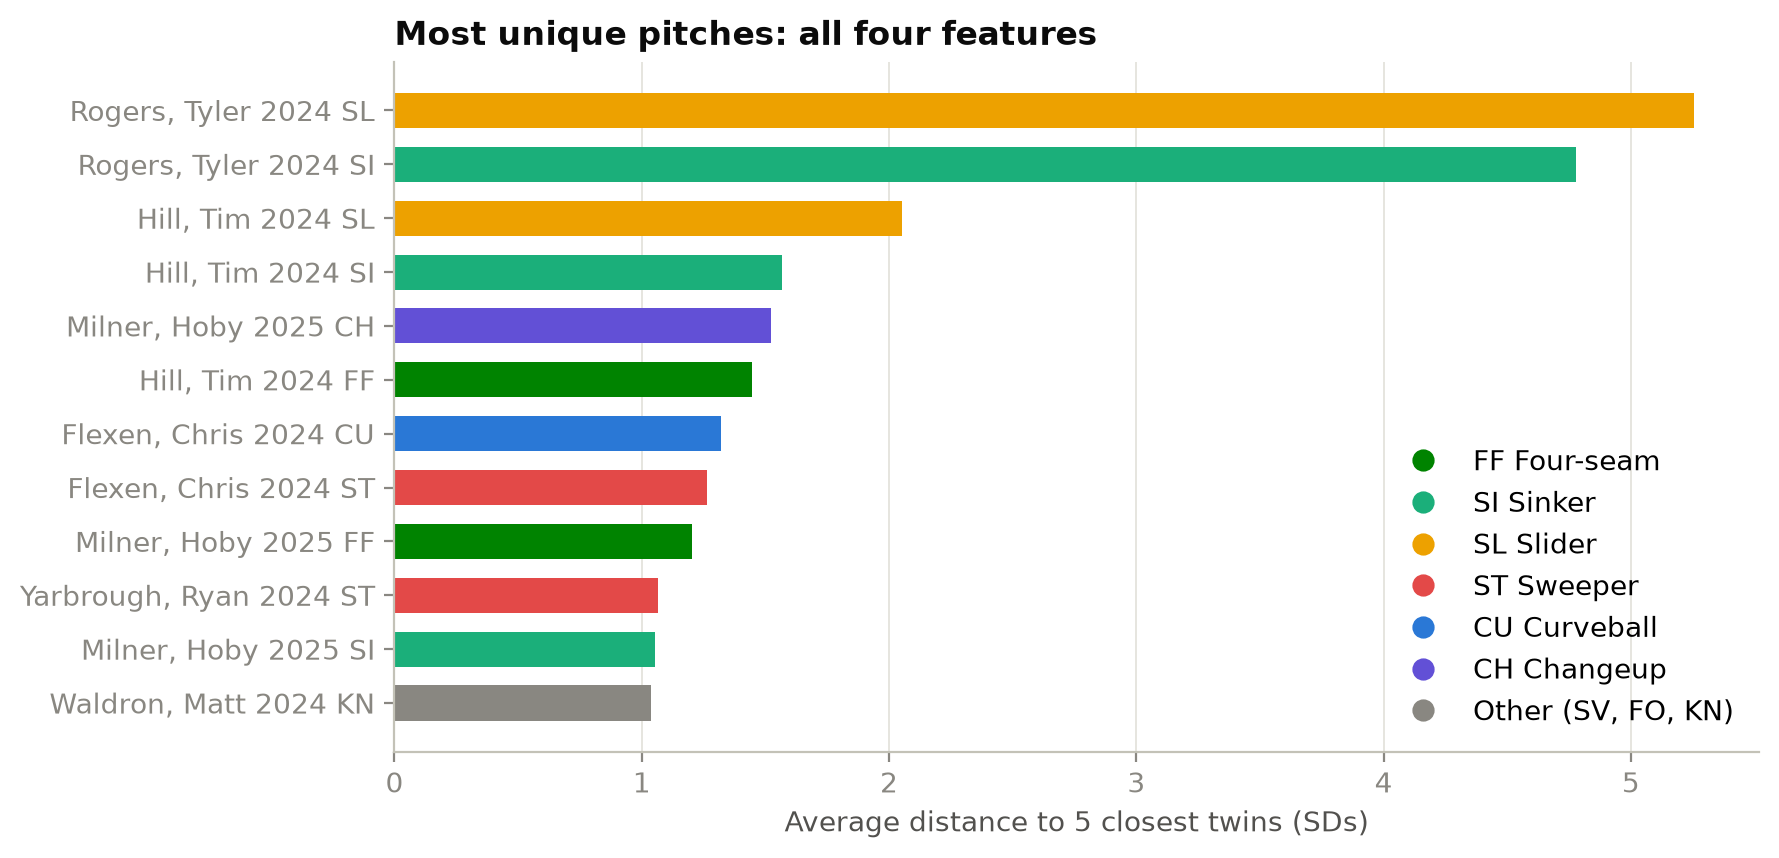

In [11]:
top_u = unique_all.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(top_u['label'], top_u['avg_dist_5'], color=top_u['type_group'].map(PITCH_COLORS), height=0.65)
ax.set_xlabel('Average distance to 5 closest twins (SDs)')
ax.set_title('Most unique pitches: all four features', loc='left')
ax.grid(axis='y', visible=False)
types_shown = [t for t in PITCH_ORDER + ['Other'] if t in set(top_u['type_group'])]
pitch_legend(ax, types=types_shown, loc='lower right')
plt.tight_layout()
plt.show()

**One pitcher dominates the list.** Look at the `ball_angle` column: the top of the list is a **submariner**. Arm angle is per-pitcher, so an extreme arm slot makes *every* pitch he throws look unique. The arm-angle distribution shows why:

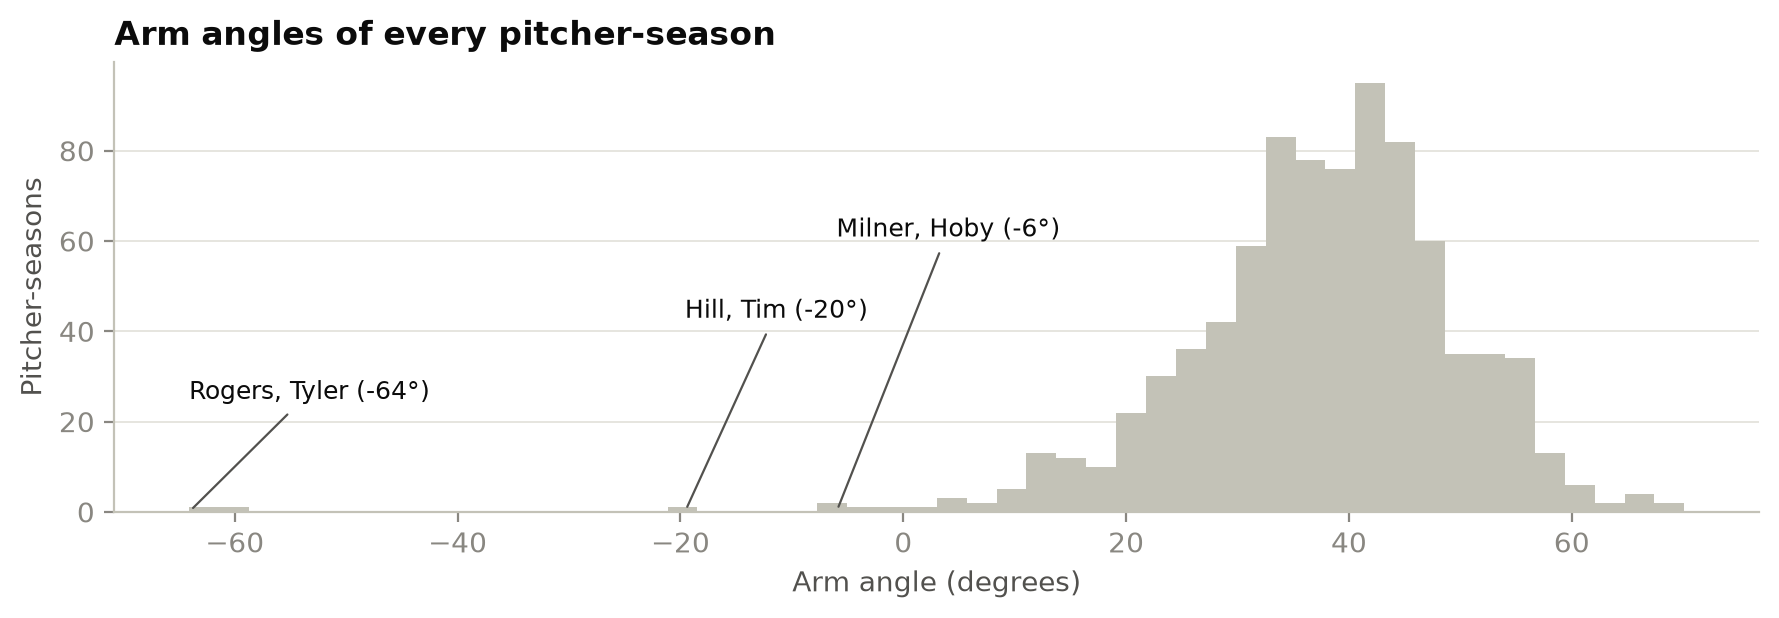

In [12]:
slots = data.drop_duplicates(['id', 'year'])
lowest = slots.sort_values('ball_angle').drop_duplicates('id').head(3)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(slots['ball_angle'], bins=50, color=GRAY)
for i, (_, row) in enumerate(lowest.iterrows()):
    ax.annotate(f"{row['name']} ({row['ball_angle']:.0f}°)", xy=(row['ball_angle'], 0),
                xytext=(row['ball_angle'], 25 + 18 * i), color=INK, fontsize=9,
                arrowprops=dict(arrowstyle='-', color=SUBTLE, lw=0.8))
ax.set_xlabel('Arm angle (degrees)')
ax.set_ylabel('Pitcher-seasons')
ax.set_title('Arm angles of every pitcher-season', loc='left')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

The lowest arm angle sits **far** from everyone else, while the other low-slot pitchers are much closer to the pack. Because arm angle is 1 of our 4 features, it alone puts this pitcher's whole arsenal at the top.

That's a legitimate answer ("the most unique pitches come from the most unique delivery"), but it raises a fair follow-up: **which pitches are unique because of the *ball's flight*, not the delivery?**

### Uniqueness 3: Pitch shape only (drop arm angle)
Re-run Method 2 using only velocity and movement:

In [13]:
SHAPE = ['avg_speed', 'arm_break', 'pitcher_break_z_induced']
Z_shape = (data[SHAPE] - data[SHAPE].mean()) / data[SHAPE].std()
shape_dist = blank_out(data, euclidean_distances(Z_shape))
data['avg_dist_5_shape'] = np.sort(shape_dist, axis=1)[:, :5].mean(axis=1)

unique_shape = data.sort_values('avg_dist_5_shape', ascending=False).drop_duplicates(['id', 'pitch_type'])
unique_shape[show + ['avg_dist_5_shape']].head(12).round(2)

,label,pitch_type_qualified,n_pitches,avg_speed,arm_break,pitcher_break_z_induced,ball_angle,avg_dist_5_shape
1139,"Rogers, Tyler 2024 SL",True,356,73.6,-8.9,15.4,-64.1,1.18
625,"Yarbrough, Ryan 2024 ST",True,411,71.3,-15.0,6.1,13.5,0.99
1319,"Bassitt, Chris 2025 ST",False,164,72.6,-19.2,-0.8,32.0,0.85
318,"Waldron, Matt 2024 KN",True,936,77.6,5.6,-3.4,28.6,0.71
1078,"Suter, Brent 2024 CH",False,202,75.5,8.9,11.7,55.6,0.68
1163,"Clase, Emmanuel 2024 FC",True,765,99.5,-3.3,11.5,53.3,0.65
2155,"Doval, Camilo 2025 SI",False,135,96.6,7.5,5.1,15.7,0.58
2354,"Yarbrough, Ryan 2025 CH",False,209,77.9,17.4,-2.0,13.0,0.57
2138,"Williams, Devin 2025 CH",True,584,83.7,19.2,-4.7,21.0,0.55
2068,"Milner, Hoby 2025 CH",False,201,81.1,16.0,-4.1,-6.0,0.54


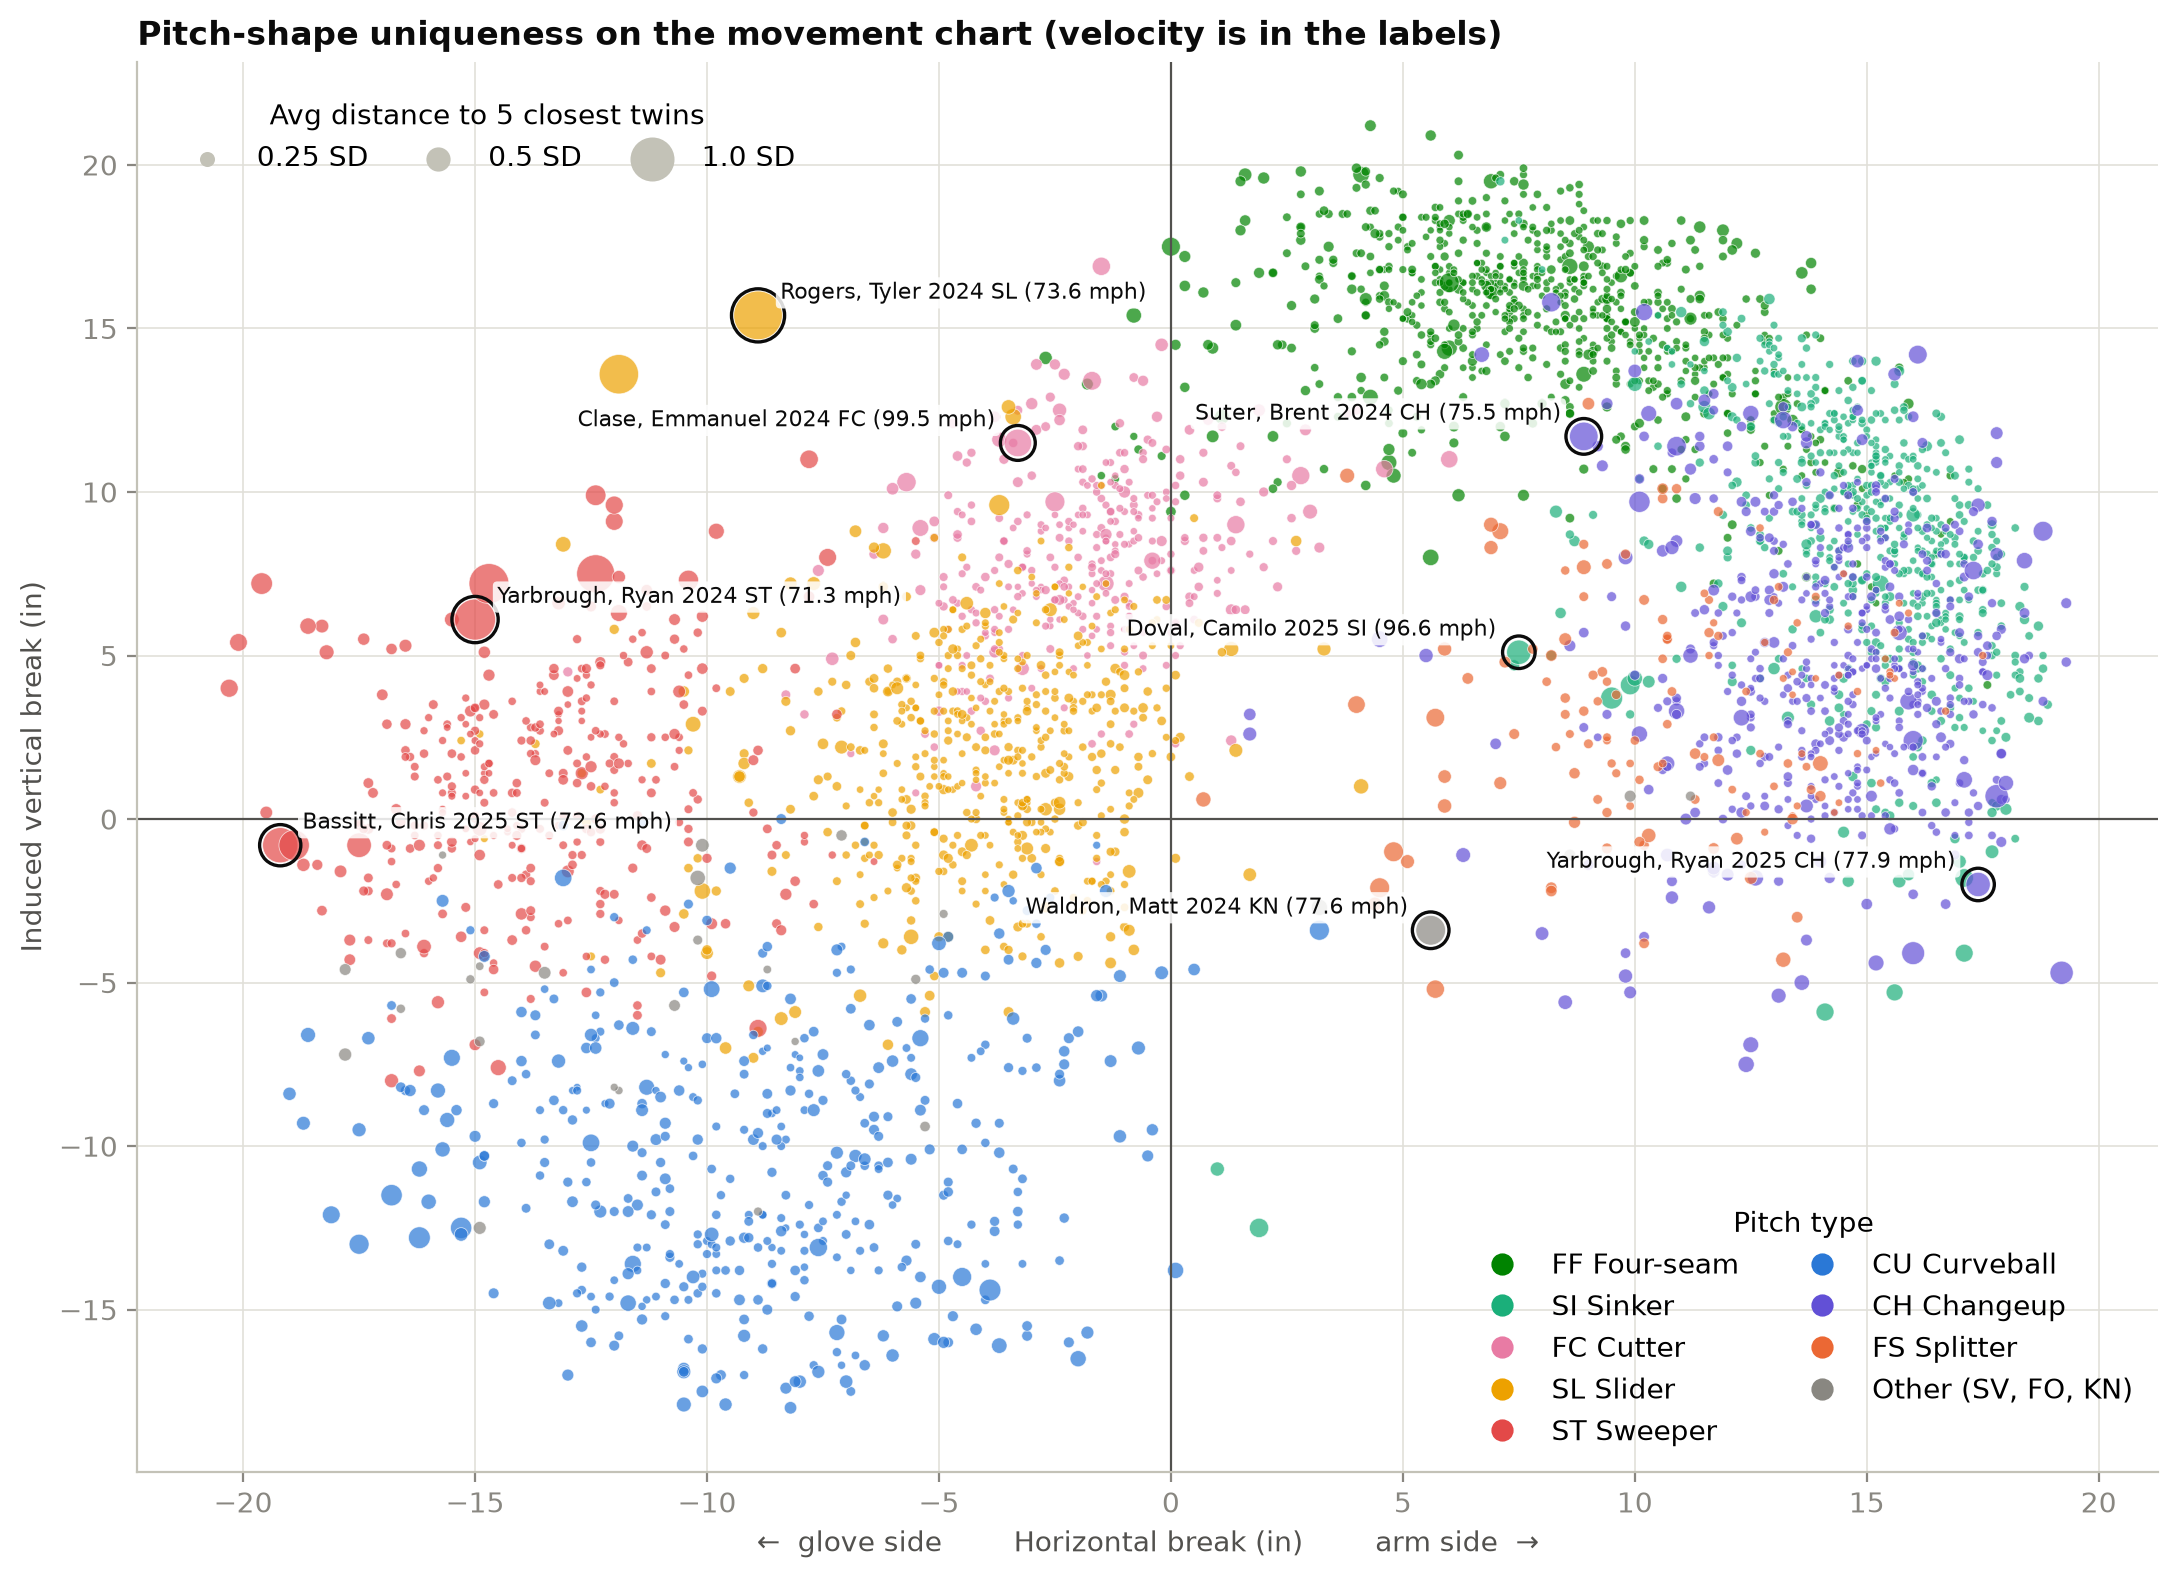

In [14]:
# Color = pitch type, dot size = uniqueness (bigger = farther from its 5 closest twins)
biggest = data['avg_dist_5_shape'].max()
def dot_size(score):
    return 6 + 300 * (score / biggest) ** 2

fig, ax = plt.subplots(figsize=(11, 8))
ax.axhline(0, color=SUBTLE, lw=0.8)
ax.axvline(0, color=SUBTLE, lw=0.8)
pitch_scatter(ax, data, 'arm_break', 'pitcher_break_z_induced', size=dot_size(data['avg_dist_5_shape']),
              alpha=0.7, type_labels=False)

top8 = unique_shape.head(8)
ax.scatter(top8['arm_break'], top8['pitcher_break_z_induced'], s=dot_size(top8['avg_dist_5_shape']) + 60,
           facecolor='none', edgecolor=INK, linewidth=1.2)
for _, row in top8.iterrows():
    right_side = row['arm_break'] > -5                    # labels for dots right of -5 go to the LEFT of the dot
    ax.annotate(f"{row['label']} ({row['avg_speed']:.1f} mph)",
                (row['arm_break'], row['pitcher_break_z_induced']),
                xytext=(-8 if right_side else 8, 6), textcoords='offset points',
                ha='right' if right_side else 'left', fontsize=8, color=INK,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))
ax.set_xlabel('←  glove side        Horizontal break (in)        arm side  →')
ax.set_ylabel('Induced vertical break (in)')
ax.set_title('Pitch-shape uniqueness on the movement chart (velocity is in the labels)', loc='left')

# Two legends, placed in the chart's empty corners: colors = pitch type, sizes = uniqueness
type_legend = pitch_legend(ax, loc='lower right', ncol=2, title='Pitch type')
ax.add_artist(type_legend)
size_handles = [ax.scatter([], [], s=dot_size(v), color=GRAY) for v in [0.25, 0.5, 1.0]]
ax.legend(size_handles, ['0.25 SD', '0.5 SD', '1.0 SD'], title='Avg distance to 5 closest twins',
          loc='upper left', ncol=3, frameon=False, borderpad=1, columnspacing=1.5)
plt.tight_layout()
plt.show()

Even with arm angle removed, **Tyler Rogers' 2024 slider stays #1**. It's a *rising* slider: +15 inches of induced vertical break at 73.6 mph while breaking to the glove side. On the movement chart it sits up and to the left, where almost no other pitch lives. (Submarine pitchers release from below, so their sliders can carry upward.) Below it come pitches that are extreme on mostly *one* dimension: Ryan Yarbrough's 71 mph sweeper with carry, Chris Bassitt's 73 mph sweeper with ~19 inches of sweep, Matt Waldron's knuckleball, and Emmanuel Clase's 99.5 mph cutter.

### Uniqueness 4: Cosine-based ("an unusual combination")
Use cosine similarity instead of distance: a pitch is unique if **no other pitch has a similar *profile***, i.e., its best cosine similarity is low. This asks a different question from distance. It's not "how extreme?" but "**is this mix of traits unusual?**"

In [15]:
data['cos_twin'] = twins_cos['twin'].to_numpy()
data['best_cosine'] = twins_cos['score'].to_numpy()
data['dist_from_avg'] = np.sqrt((Z ** 2).sum(axis=1))      # arrow length: how far from the league-average pitch

unique_cos = data.sort_values('best_cosine').drop_duplicates(['id', 'pitch_type'])
unique_cos[show + ['cos_twin', 'best_cosine', 'dist_from_avg']].head(10).round(3)

,label,pitch_type_qualified,n_pitches,avg_speed,arm_break,pitcher_break_z_induced,ball_angle,cos_twin,best_cosine,dist_from_avg
1456,"Hendricks, Kyle 2025 FF",True,385,86.5,5.9,14.3,42.6,"Bellozo, Valente 2024 FF",0.919,1.248
2891,"Seymour, Ian 2026 SL",False,138,83.2,-3.4,12.3,41.1,"Pérez, Martín 2026 FC",0.932,1.429
318,"Waldron, Matt 2024 KN",True,936,77.6,5.6,-3.4,28.6,"Bruihl, Justin 2026 CH",0.933,2.288
2905,"Ober, Bailey 2026 FF",True,660,88.0,6.9,16.1,28.2,"Eisert, Brandon 2025 FF",0.940,1.590
3050,"Lauer, Eric 2026 FC",True,411,87.6,-1.4,8.5,37.4,"Patrick, Chad 2025 FC",0.946,0.620
996,"Morejon, Adrian 2024 KN",False,83,86.2,8.6,-1.1,42.8,"Miller, Bryce 2024 FS",0.947,1.085
3674,"Fermin, José 2026 SL",True,573,90.5,1.4,2.1,44.0,"Faucher, Calvin 2024 FC",0.949,0.787
718,"Megill, Tylor 2024 FS",False,103,84.7,4.4,-2.6,36.8,"Lorenzen, Michael 2026 CU",0.952,1.149
1619,"Gilbert, Logan 2025 FS",True,423,81.7,4.8,-1.0,40.2,"Neris, Héctor 2024 FS",0.952,1.403
3544,"Hart, Kyle 2026 FS",False,214,85.5,8.2,-2.2,38.3,"Maeda, Kenta 2024 FS",0.954,1.131


In [16]:
# Where does the Method 1-2 winner rank under cosine uniqueness?
data['cosine_unique_rank'] = data['best_cosine'].rank().astype(int)
top_id = unique_all.iloc[0]['id']
data.loc[data['id'] == top_id, ['label', 'cos_twin', 'best_cosine', 'cosine_unique_rank']]

,label,cos_twin,best_cosine,cosine_unique_rank
1138,"Rogers, Tyler 2024 SI","Herget, Jimmy 2025 SL",0.980395,72
1139,"Rogers, Tyler 2024 SL","Lopez, Jacob 2026 FC",0.995285,825
3609,"Rogers, Tyler 2026 SI","Castillo, Luis 2024 SL",0.975821,56
3610,"Rogers, Tyler 2026 SL","Yarbrough, Ryan 2025 FC",0.994700,709


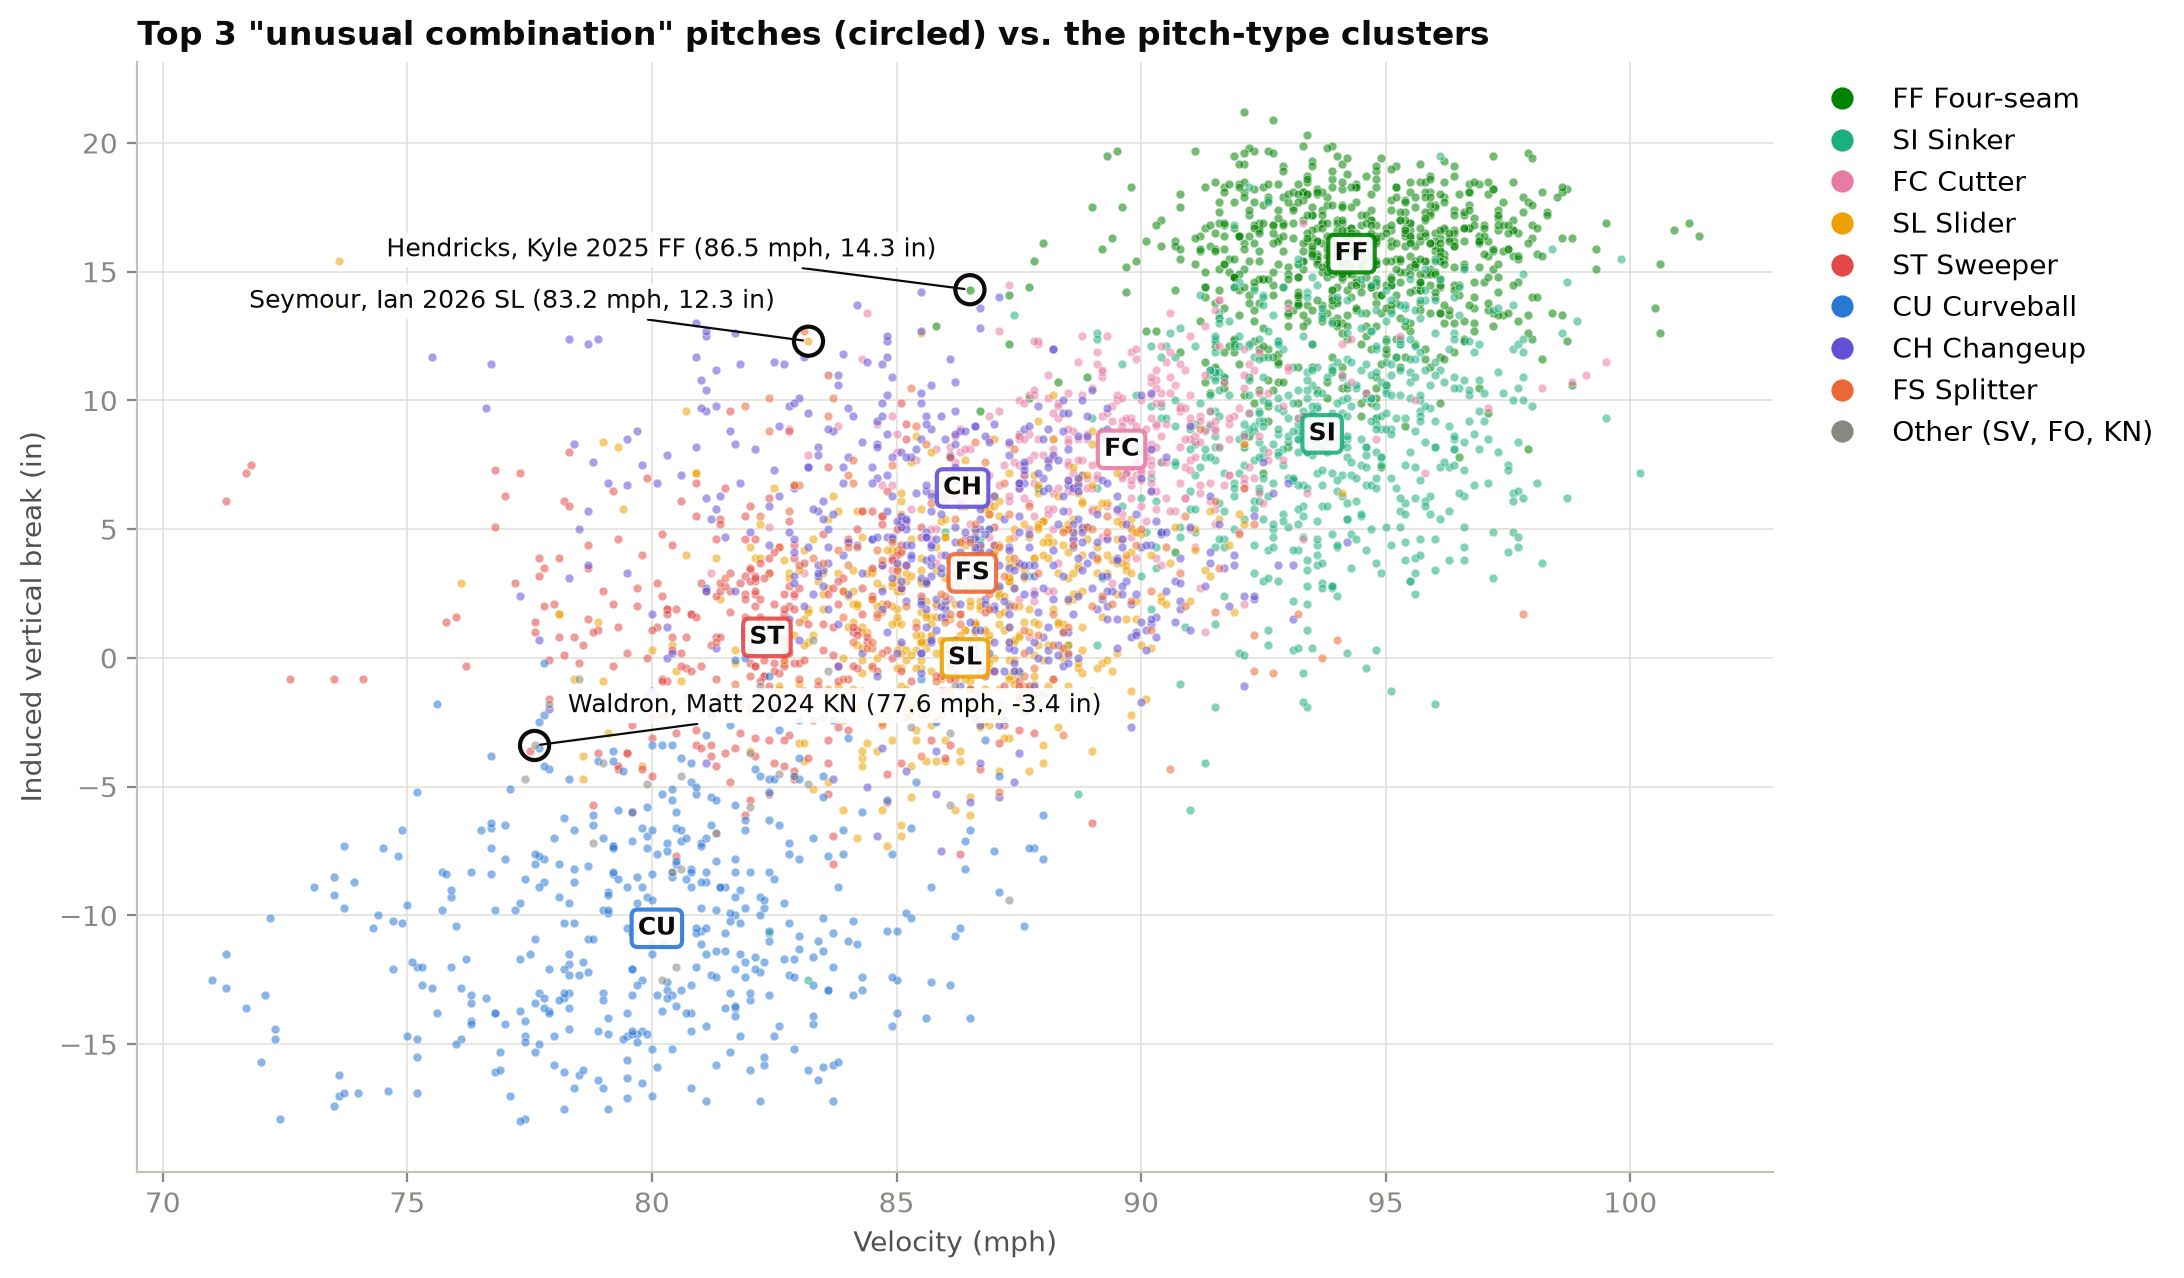

In [17]:
# Where do the top 3 "unusual combination" pitches sit relative to the pitch-type clusters?
top3_cos = unique_cos.head(3)

fig, ax = plt.subplots(figsize=(11, 6.5))
pitch_scatter(ax, data, 'avg_speed', 'pitcher_break_z_induced', alpha=0.55, nudge=NUDGE_VELO)
ax.scatter(top3_cos['avg_speed'], top3_cos['pitcher_break_z_induced'], s=110, facecolor='none',
           edgecolor=INK, linewidth=1.5)
for _, row in top3_cos.iterrows():
    to_right = row['avg_speed'] < 82                   # slow pitches: label to the right so it stays on the chart
    ax.annotate(f"{row['label']} ({row['avg_speed']:.1f} mph, {row['pitcher_break_z_induced']:.1f} in)",
                (row['avg_speed'], row['pitcher_break_z_induced']), xytext=(12 if to_right else -12, 12),
                textcoords='offset points', ha='left' if to_right else 'right', fontsize=9, color=INK,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.9),
                arrowprops=dict(arrowstyle='-', color=INK, lw=0.8))
ax.set_xlabel('Velocity (mph)')
ax.set_ylabel('Induced vertical break (in)')
ax.set_title('Top 3 "unusual combination" pitches (circled) vs. the pitch-type clusters', loc='left')
pitch_legend(ax, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**A completely different list.** Three things stand out:
* **On the chart, they mix traits of two pitch types.** Hendricks' four-seamer has four-seam ride (14 in) but sits ~8 mph to the left of the four-seam cluster, among the changeups and cutters. Seymour's slider has ~10 inches more ride than a typical slider. Each sits on the edge of a cluster that isn't its own.
* Most cosine-unique pitches have **short arrows** (`dist_from_avg` mostly 0.6–1.6 SD). They aren't extreme; they're *odd mixtures*. Kyle Hendricks' four-seamer tops the list: 14 inches of ride (a "riding fastball" trait) at only 86.5 mph (a changeup-like speed). No other pitch has quite that combination.
* The submariner **isn't unique at all** by cosine. His arrow is extremely long, but it points the same way as other low-slot pitchers' arrows. Cosine sees him as "a more extreme version of a sidearmer," which is fair as far as direction goes but misses how extreme he is.

**Caveat:** for pitches very close to league average, the arrow is tiny and its direction is shaky, so small measurement noise can swing cosine a lot. Treat this list as "interesting combinations," not "most unique."

### Uniqueness 5: Within pitch type
A sweeper competes for hitters' attention with other sweepers, not with sinkers. So compare each pitch **only to pitches of the same type**, standardizing within that type. This answers "who throws the most unusual *slider*?" (Types with fewer than 20 rows, KN and FO, are skipped because there's no "normal" to compare against.)

In [18]:
results = []
for pitch_type, group in data.groupby('pitch_type'):
    if len(group) < 20:
        continue
    group = group.reset_index(drop=True)
    Z_g = (group[FEATURES] - group[FEATURES].mean()) / group[FEATURES].std()
    dist_g = blank_out(group, euclidean_distances(Z_g))
    group['avg_dist_5_within'] = np.sort(dist_g, axis=1)[:, :5].mean(axis=1)
    results.append(group)

within = pd.concat(results)
most_unique_by_type = (within.sort_values('avg_dist_5_within', ascending=False)
                             .drop_duplicates('pitch_type')
                             .sort_values('pitch_type'))
most_unique_by_type[show + ['avg_dist_5_within']].round(2)

,label,pitch_type_qualified,n_pitches,avg_speed,arm_break,pitcher_break_z_induced,ball_angle,avg_dist_5_within
295,"Milner, Hoby 2025 CH",False,201,81.1,16.0,-4.1,-6.0,2.24
20,"Flexen, Chris 2024 CU",True,342,72.0,-7.2,-15.7,70.1,1.82
87,"Strickland, Hunter 2024 FC",True,363,84.0,-13.0,4.5,31.7,3.34
245,"Hill, Tim 2024 FF",False,256,90.7,17.6,4.1,-19.6,2.72
96,"Griffin, Foster 2026 FS",False,160,81.3,0.7,0.6,44.7,1.76
175,"Rogers, Tyler 2024 SI",True,640,82.4,1.0,-10.7,-64.1,8.99
166,"Rogers, Tyler 2024 SL",True,356,73.6,-8.9,15.4,-64.1,6.91
53,"Yarbrough, Ryan 2024 ST",True,411,71.3,-15.0,6.1,13.5,2.34
22,"Vodnik, Victor 2026 SV",False,70,87.3,-5.3,-9.4,43.7,2.83


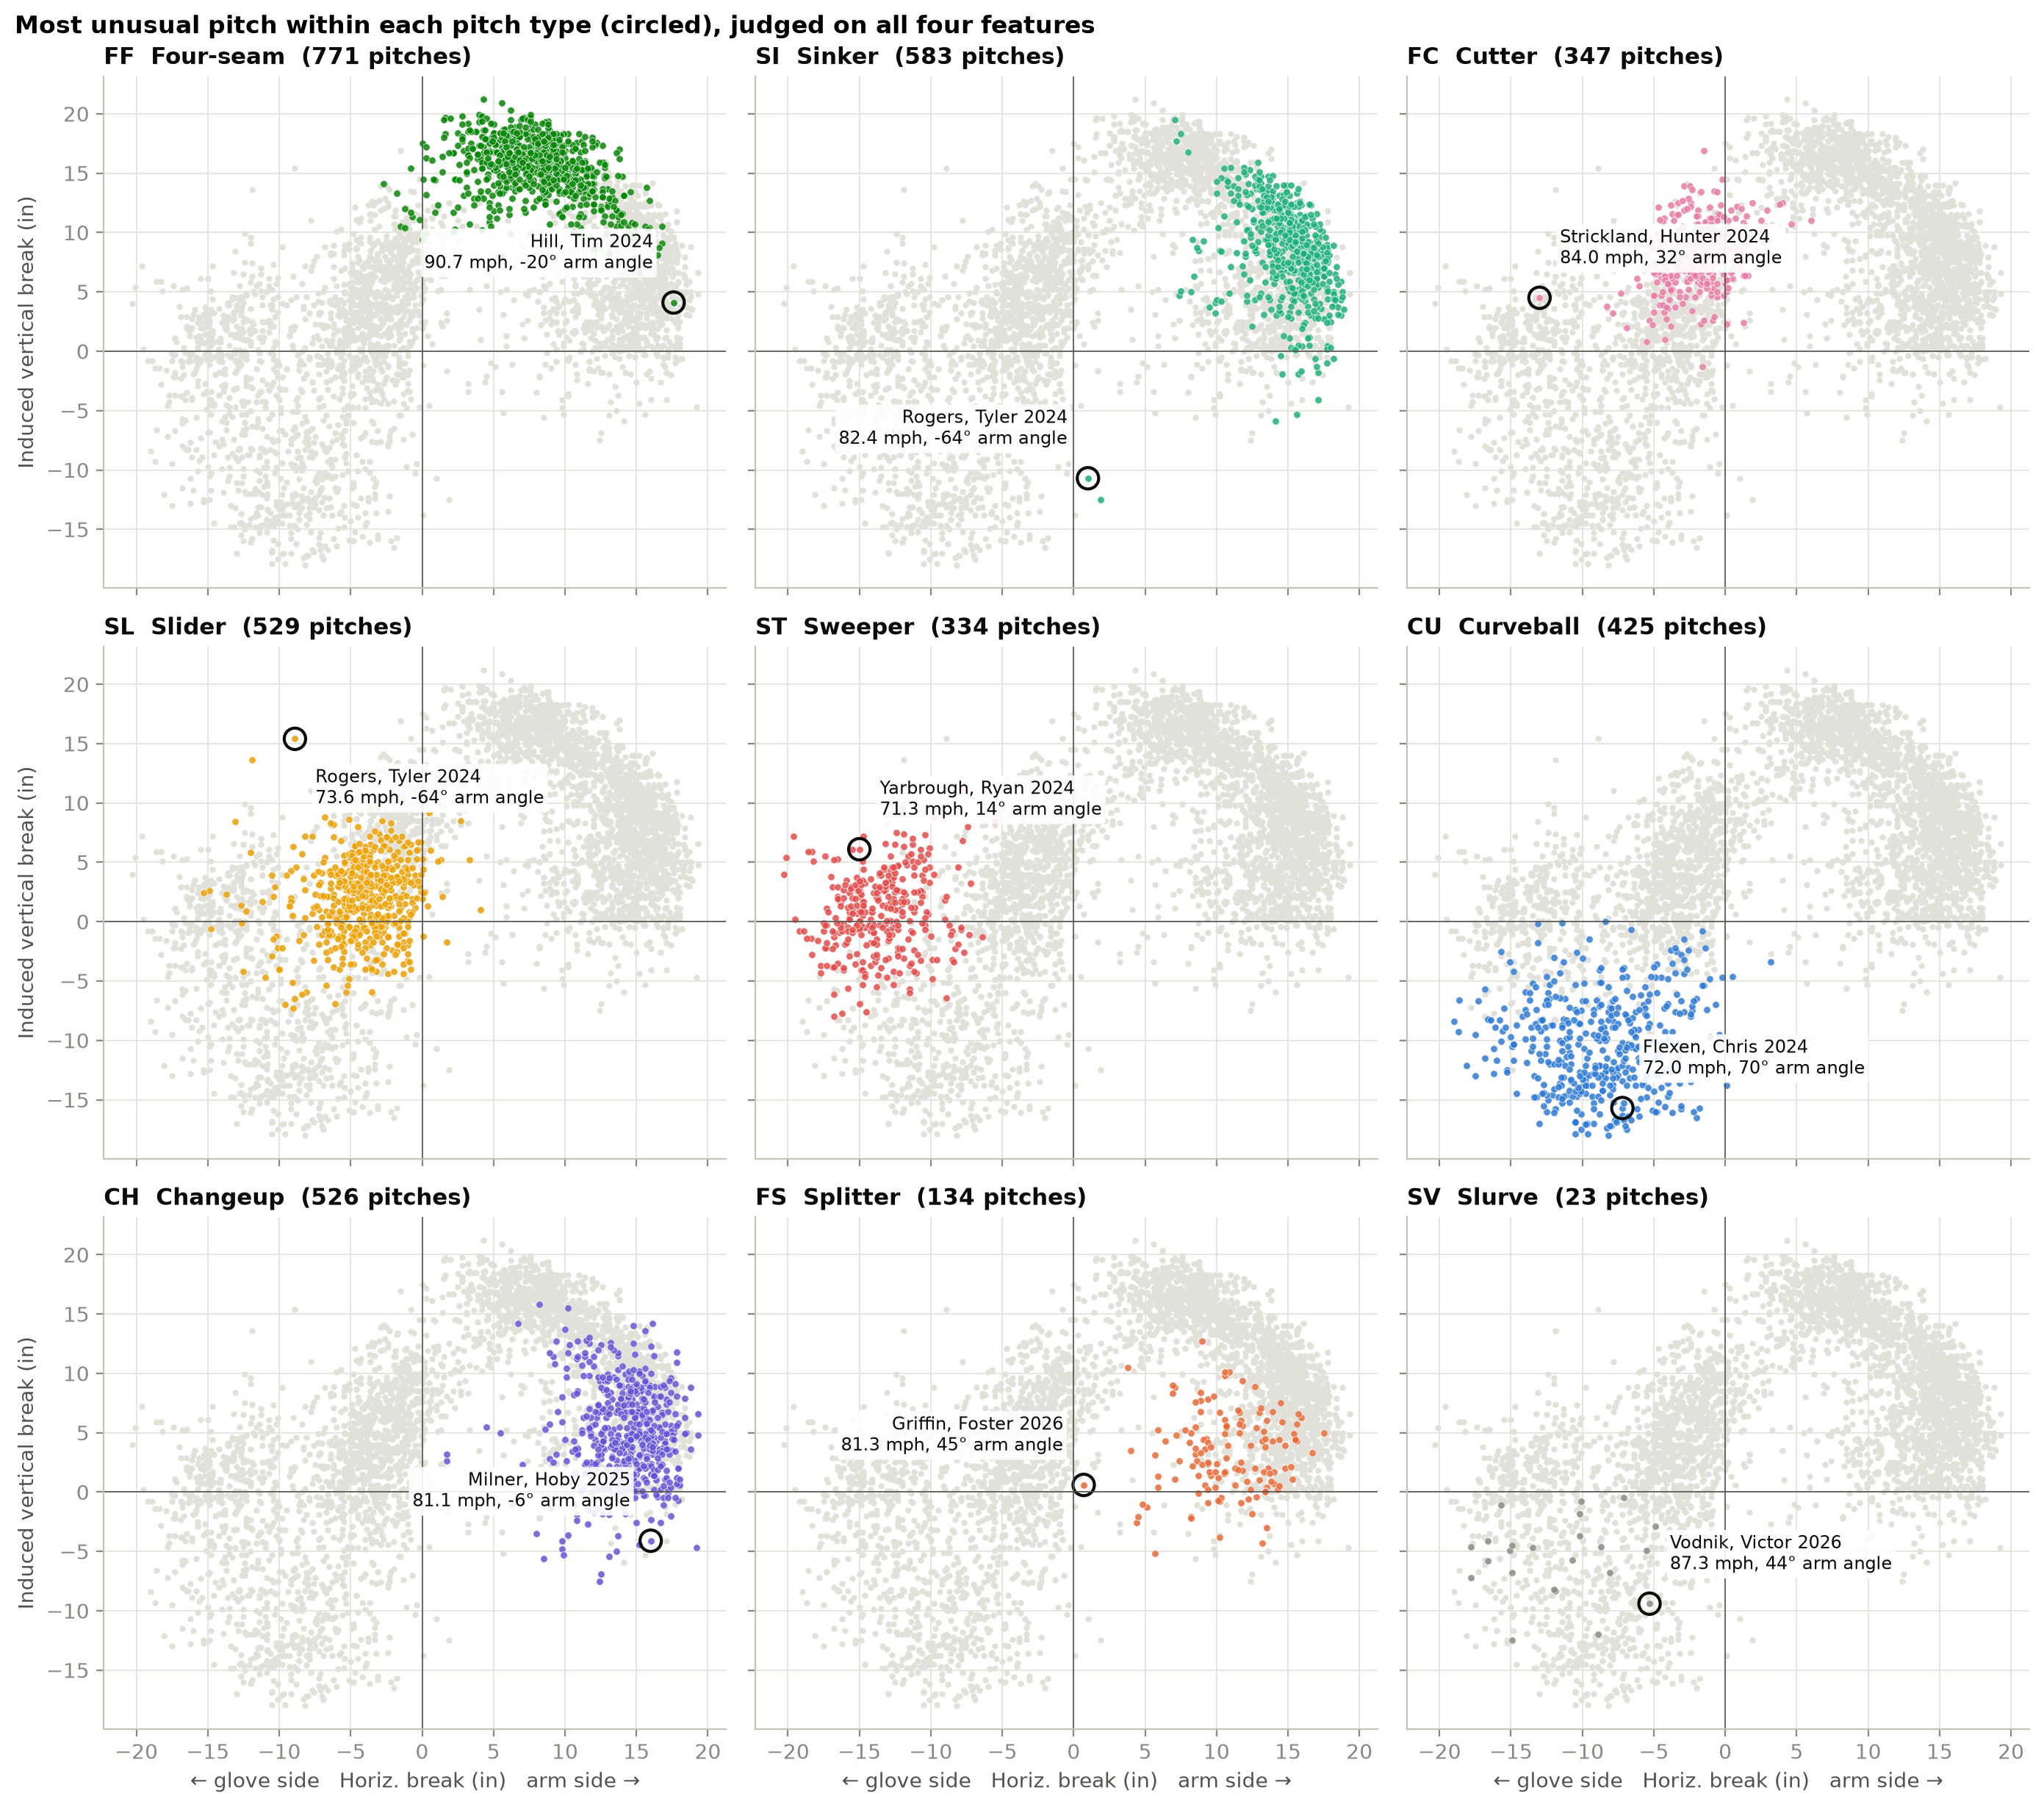

In [19]:
# One small chart per pitch type: that type in its color, every other pitch in light gray for context,
# and the most unusual pitch of that type circled
type_list = [t for t in PITCH_ORDER + ['SV'] if t in set(within['pitch_type'])]

fig, axes = plt.subplots(3, 3, figsize=(14, 12.5), sharex=True, sharey=True)
for ax, t in zip(axes.flat, type_list):
    ax.scatter(data['arm_break'], data['pitcher_break_z_induced'], s=4, color='#e1e0d9')
    group = within[within['pitch_type'] == t]
    color = PITCH_COLORS.get(t, PITCH_COLORS['Other'])
    ax.scatter(group['arm_break'], group['pitcher_break_z_induced'], s=12, color=color, alpha=0.8,
               edgecolor='white', linewidth=0.3)

    star = group.sort_values('avg_dist_5_within', ascending=False).iloc[0]
    ax.scatter(star['arm_break'], star['pitcher_break_z_induced'], s=110, facecolor='none', edgecolor=INK, linewidth=1.5)
    to_left = star['arm_break'] > 0                    # write the label toward the middle of the chart
    to_below = star['pitcher_break_z_induced'] > 10
    ax.annotate(f"{star['name']} {star['year']}\n{star['avg_speed']:.1f} mph, {star['ball_angle']:.0f}° arm angle",
                (star['arm_break'], star['pitcher_break_z_induced']),
                xytext=(-10 if to_left else 10, -14 if to_below else 14), textcoords='offset points',
                ha='right' if to_left else 'left', va='top' if to_below else 'bottom', fontsize=8.5, color=INK,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.9))
    ax.axhline(0, color=SUBTLE, lw=0.6)
    ax.axvline(0, color=SUBTLE, lw=0.6)
    ax.set_title(f"{t}  {PITCH_NAMES[t]}  ({len(group)} pitches)", loc='left', fontsize=11)

for ax in axes[-1]:
    ax.set_xlabel('← glove side   Horiz. break (in)   arm side →')
for ax in axes[:, 0]:
    ax.set_ylabel('Induced vertical break (in)')
fig.suptitle('Most unusual pitch within each pitch type (circled), judged on all four features',
             fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

**Reading the within-type winners:**
* **Not every circled pitch is a movement outlier.** Chris Flexen's curveball sits *inside* the curveball cluster. What makes it unusual is its 70° arm angle, which the movement axes can't show, so each label lists velocity and arm angle too. Rogers' sinker and Hunter Strickland's cutter, by contrast, sit far from their own clusters.
* **Arm angle still drives several rows.** Rogers has the most unusual sinker *and* slider. Tim Hill's four-seamer (−20°), Hoby Milner's changeup (−6°), and Chris Flexen's curveball (70°, the highest slot in the data) are also slot-driven.
* **The rows driven by pitch shape are the interesting ones.** Hunter Strickland's 2024 cutter breaks 13 inches to the glove side at 84 mph, so it moves like a slider and might be a labeling question. Ryan Yarbrough's sweeper is the slowest in the league, and it carries instead of dropping.
* Watch the `pitch_type_qualified` column. Victor Vodnik's slurve (70 pitches) and Foster Griffin's splitter (160 pitches) are small samples.

### Robustness: uniqueness among qualified pitches only
Small samples can produce odd averages (a pitch thrown 51 times can look strange by chance). Re-run Method 2 using only qualified pitches:

In [20]:
q = data[data['pitch_type_qualified']].reset_index(drop=True)
Z_q = (q[FEATURES] - q[FEATURES].mean()) / q[FEATURES].std()
q['avg_dist_5'] = np.sort(blank_out(q, euclidean_distances(Z_q)), axis=1)[:, :5].mean(axis=1)
q.sort_values('avg_dist_5', ascending=False).drop_duplicates(['id', 'pitch_type'])[show + ['avg_dist_5']].head(8).round(2)

,label,pitch_type_qualified,n_pitches,avg_speed,arm_break,pitcher_break_z_induced,ball_angle,avg_dist_5
659,"Rogers, Tyler 2024 SL",True,356,73.6,-8.9,15.4,-64.1,5.70
658,"Rogers, Tyler 2024 SI",True,640,82.4,1.0,-10.7,-64.1,5.18
671,"Hill, Tim 2024 SI",True,675,88.7,15.6,-5.3,-19.6,1.57
130,"Flexen, Chris 2024 CU",True,342,72.0,-7.2,-15.7,70.1,1.48
247,"Waldron, Matt 2024 KN",True,936,77.6,5.6,-3.4,28.6,1.16
1210,"Milner, Hoby 2025 ST",True,406,78.2,-15.0,0.1,-6.0,1.11
1211,"Milner, Hoby 2025 SI",True,386,87.5,18.2,-0.6,-6.0,1.10
443,"Yarbrough, Ryan 2024 ST",True,411,71.3,-15.0,6.1,13.5,1.09


---
## Part 4: Summary

### Which pitches are the most unique?

| Method | Most unique pitch | Why |
|---|---|---|
| 1. Distance to closest twin | Tyler Rogers 2024 SL | −64° submarine arm angle |
| 2. Avg distance to 5 closest | Tyler Rogers 2024 SL (his SI is #2) | same |
| 3. Pitch shape only (no arm angle) | Tyler Rogers 2024 SL → Ryan Yarbrough 2024 ST → Chris Bassitt 2025 ST | rising slider: +15 in IVB at 73.6 mph |
| 4. Cosine ("unusual mix") | Kyle Hendricks 2025 FF | 14 in of ride at only 86.5 mph |
| 5. Within pitch type | Rogers (most unusual SI *and* SL); Strickland 2024 FC; Yarbrough 2024 ST | slot, or a cutter that moves like a slider |
| Qualified pitches only | Tyler Rogers 2024 SL | n/a |

**Answer:** **Tyler Rogers' 2024 slider** ranks #1 under every distance-based method, with or without arm angle, and on qualified pitches only. His −64° submarine slot alone makes his whole arsenal unique. Even judged purely on ball flight, his slider rises (+15 in IVB) while breaking glove side at 73 mph, a pitch shape nobody else in the league throws. For "unique *combination*" (cosine), the answer is Kyle Hendricks' slow, riding four-seamer.

### What these methods can't see (and ideas for next steps)
* **Equal weighting is a choice.** Z-scoring gives each feature one equal vote, so arm angle is 25% of the score. You could weight features differently, or drop arm angle as in Method 3.
* **The features are correlated.** Fast pitches also tend to ride and run arm side (fastball traits), so Euclidean distance partly counts "fastball-ness" more than once. **Mahalanobis distance** corrects for correlation and would be a natural next step.
* **Averages hide variability.** A knuckleball's defining trait is that it's unpredictable *pitch to pitch*. Season averages can't capture that, which is why Waldron's knuckleball only ranks around #4–12.
* **More ingredients:** spin rate, extension, and release height would sharpen the comparisons. Two pitches with identical averages can still look different to a hitter if they come out of different release points.